In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier

df = pd.read_csv("../data/processed/telco_clean.csv")
drop_cols = ["customerid", "count", "country", "state", "city", "zip_code",
             "lat_long", "latitude", "longitude",
             "churn_label", "churn_score", "churn_reason", "cltv"]
y = df["churn_value"]
X = pd.get_dummies(df.drop(columns=drop_cols + ["churn_value"]), drop_first=True).astype(float)

In [2]:
model = CalibratedClassifierCV(
    XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                  eval_metric="logloss", random_state=42),
    method="isotonic", cv=5)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
df["churn_prob"] = cross_val_predict(model, X, y, cv=cv, method="predict_proba")[:, 1]

In [3]:
DISCOUNT_PCT = 0.20      # offer: 20% off monthly charges
DISCOUNT_MONTHS = 12     # for 12 months
SAVE_RATE = 0.30         # share of would-be churners the offer retains

df["offer_cost"] = DISCOUNT_PCT * df["monthly_charges"] * DISCOUNT_MONTHS
df["revenue_at_risk"] = df["churn_prob"] * df["cltv"]
df["expected_net"] = df["churn_prob"] * SAVE_RATE * df["cltv"] - df["offer_cost"]
df["target"] = df["expected_net"] > 0
print(df["target"].sum(), "customers targeted")

4412 customers targeted


In [4]:
everyone = pd.Series(True, index=df.index)
df["realized_net"] = df["churn_value"] * SAVE_RATE * df["cltv"] - df["offer_cost"]

print("Target nobody:           0")
print("Target everyone  (expected):", round(df.loc[everyone, "expected_net"].sum()))
print("Target by rule   (expected):", round(df.loc[df["target"], "expected_net"].sum()))
print("Target everyone  (actual churners):", round(df.loc[everyone, "realized_net"].sum()))
print("Target by rule   (actual churners):", round(df.loc[df["target"], "realized_net"].sum()))

Target nobody:           0
Target everyone  (expected): 1236250
Target by rule   (expected): 1493115
Target everyone  (actual churners): 1231897
Target by rule   (actual churners): 1491011


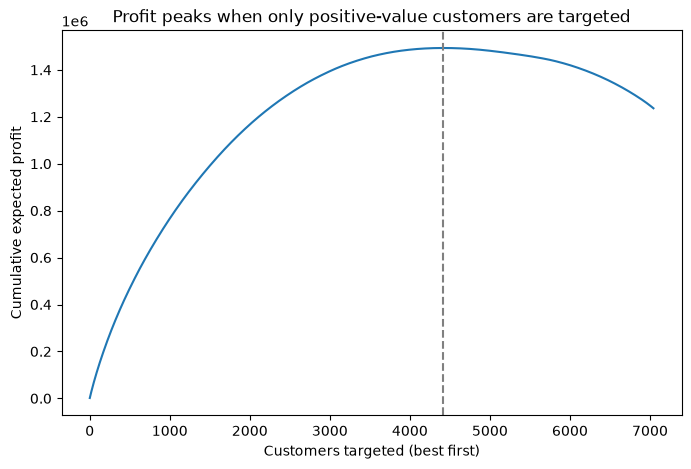

In [5]:
s = df.sort_values("expected_net", ascending=False)
cum = s["expected_net"].cumsum().values
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum) + 1), cum)
plt.axvline(df["target"].sum(), ls="--", color="gray")
plt.xlabel("Customers targeted (best first)")
plt.ylabel("Cumulative expected profit")
plt.title("Profit peaks when only positive-value customers are targeted")
plt.savefig("../reports/figures/profit_curve.png", bbox_inches="tight", dpi=150)
plt.show()

In [6]:
import shap
final = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                      eval_metric="logloss", random_state=42).fit(X, y)
sv = shap.TreeExplainer(final).shap_values(X)
df["top_reason"] = X.columns[sv.argmax(axis=1)]

df["risk_tier"] = pd.cut(df["churn_prob"], [0, 0.3, 0.6, 1.0],
                         labels=["Low", "Medium", "High"], include_lowest=True)
df["recommended_action"] = np.where(
    ~df["target"], "No action",
    np.where(df["contract"] == "Month-to-month",
             "Offer discount for 12-month contract", "Offer loyalty discount"))

cols = ["customerid", "city", "latitude", "longitude", "contract", "tenure_months",
        "internet_service", "payment_method", "monthly_charges", "cltv",
        "churn_value", "churn_prob", "risk_tier", "revenue_at_risk",
        "offer_cost", "expected_net", "target", "top_reason", "recommended_action"]
df[cols].to_csv("../data/outputs/predictions.csv", index=False)
df[cols].head()

,customerid,city,latitude,longitude,contract,tenure_months,internet_service,payment_method,monthly_charges,cltv,churn_value,churn_prob,risk_tier,revenue_at_risk,offer_cost,expected_net,target,top_reason,recommended_action
0,3668-QPYBK,Los Angeles,33.964131,-118.272783,Month-to-month,2,DSL,Mailed check,53.85,3239,1,0.280810,Low,909.544454,129.24,143.623336,True,tenure_months,Offer discount for 12-month contract
1,9237-HQITU,Los Angeles,34.059281,-118.307420,Month-to-month,2,Fiber optic,Electronic check,70.70,2701,1,0.434413,Medium,1173.349644,169.68,182.324893,True,tenure_months,Offer discount for 12-month contract
2,9305-CDSKC,Los Angeles,34.048013,-118.293953,Month-to-month,8,Fiber optic,Electronic check,99.65,5372,1,0.561368,Medium,3015.670916,239.16,665.541275,True,monthly_charges,Offer discount for 12-month contract
3,7892-POOKP,Los Angeles,34.062125,-118.315709,Month-to-month,28,Fiber optic,Electronic check,104.80,5003,1,0.144820,Low,724.536698,251.52,-34.158991,False,monthly_charges,No action
4,0280-XJGEX,Los Angeles,34.039224,-118.266293,Month-to-month,49,Fiber optic,Bank transfer (automatic),103.70,5340,1,0.090176,Low,481.541002,248.88,-104.417699,False,partner_Yes,No action


In [7]:
rows = []
for save in [0.1, 0.2, 0.3, 0.4]:
    for disc in [0.1, 0.2, 0.3]:
        cost = disc * df["monthly_charges"] * DISCOUNT_MONTHS
        net = df["churn_prob"] * save * df["cltv"] - cost
        rows.append({"save_rate": save, "discount": disc,
                     "targeted": int((net > 0).sum()),
                     "rule_profit": round(net[net > 0].sum()),
                     "blanket_profit": round(net.sum())})
sens = pd.DataFrame(rows)
sens["uplift_pct"] = ((sens["rule_profit"] / sens["blanket_profit"] - 1) * 100).round(1)
sens.to_csv("../data/outputs/sensitivity.csv", index=False)
sens

,save_rate,discount,targeted,rule_profit,blanket_profit,uplift_pct
0,0.1,0.1,3707,390623,229637,70.1
1,0.1,0.2,2041,175831,-317703,-155.3
2,0.1,0.3,1034,77669,-865043,-109.0
3,0.2,0.1,4792,1117167,1006613,11.0
4,0.2,0.2,3707,781246,459273,70.1
5,0.2,0.3,2789,530161,-88067,-702.0
6,0.3,0.1,5225,1874056,1783590,5.1
7,0.3,0.2,4412,1493115,1236250,20.8
8,0.3,0.3,3707,1171870,688910,70.1
9,0.4,0.1,5462,2639499,2560566,3.1


In [8]:
import sqlite3
con = sqlite3.connect("../data/outputs/churnguard.db")
pd.read_csv("../data/outputs/predictions.csv").to_sql("predictions", con, if_exists="replace", index=False)
pd.read_sql("SELECT COUNT(*) AS rows_loaded FROM predictions", con)

,rows_loaded
0,7043


In [9]:
for q in open("../sql/kpi_queries.sql").read().split(";"):
    if q.strip():
        display(pd.read_sql(q, con))

,customers,churned,churn_pct
0,7043,1869,26.5


,contract,customers,churn_pct
0,Month-to-month,3875,42.7
1,One year,1473,11.3
2,Two year,1695,2.8


,payment_method,customers,churn_pct
0,Electronic check,2365,45.3
1,Mailed check,1612,19.1
2,Bank transfer (automatic),1544,16.7
3,Credit card (automatic),1522,15.2


,internet_service,customers,churn_pct
0,Fiber optic,3096,41.9
1,DSL,2421,19.0
2,No,1526,7.4


,tenure_band,customers,churn_pct
0,0-6,1481,52.9
1,7-12,705,35.9
2,13-24,1024,28.7
3,25+,3833,14.0


,contract,cltv_lost
0,Month-to-month,6757185
1,One year,750522
2,Two year,247549


,risk_tier,customers,revenue_at_risk
0,High,863,2591104.0
1,Low,4331,1814618.0
2,Medium,1849,3364044.0


,contract,targeted,expected_profit
0,Month-to-month,3553,1390830.0
1,One year,718,92316.0
2,Two year,141,9969.0


,customerid,contract,churn_prob,cltv,expected_net,recommended_action
0,0295-PPHDO,Month-to-month,1.00,5962,1560.0,Offer discount for 12-month contract
1,5178-LMXOP,Month-to-month,1.00,5795,1510.0,Offer discount for 12-month contract
2,6996-KNSML,Month-to-month,0.95,5919,1500.0,Offer discount for 12-month contract
3,6894-LFHLY,Month-to-month,0.98,5571,1457.0,Offer discount for 12-month contract
4,2506-TNFCO,Month-to-month,0.91,5948,1450.0,Offer discount for 12-month contract
5,2868-MZAGQ,Month-to-month,0.98,5533,1438.0,Offer discount for 12-month contract
6,1761-AEZZR,Month-to-month,0.97,5593,1430.0,Offer discount for 12-month contract
7,4806-HIPDW,Month-to-month,0.94,5644,1429.0,Offer discount for 12-month contract
8,6416-TVAIH,Month-to-month,0.92,5753,1420.0,Offer discount for 12-month contract
9,9497-QCMMS,Month-to-month,0.99,5536,1415.0,Offer discount for 12-month contract


,top_reason,customers
0,tenure_months,1703
1,internet_service_Fiber optic,924
2,contract_Two year,593
3,monthly_charges,577
4,dependents_Yes,385
5,payment_method_Electronic check,119
6,phone_service_Yes,45
7,partner_Yes,34
8,senior_citizen_Yes,15
9,paperless_billing_Yes,9


In [10]:
idx = sv.argmax(axis=1)
vals = X.values[np.arange(len(X)), idx]
feats = X.columns[idx]

reason_map = {
    ("tenure_months", None): "Short tenure",
    ("monthly_charges", None): "High monthly charges",
    ("total_charges", None): "Low lifetime spend",
    ("contract_Two year", 0): "No two-year contract",
    ("contract_One year", 0): "No one-year contract",
    ("internet_service_Fiber optic", 1): "Fiber optic service",
    ("dependents_Yes", 0): "No dependents",
    ("payment_method_Electronic check", 1): "Pays by electronic check",
    ("phone_service_Yes", 0): "No phone service",
    ("partner_Yes", 1): "Has a partner",
    ("senior_citizen_Yes", 1): "Senior citizen",
    ("paperless_billing_Yes", 1): "Paperless billing",
}

def readable(f, v):
    return reason_map.get((f, None)) or reason_map.get((f, int(v))) \
        or f.replace("_", " ") + (" = yes" if v else " = no")

df["top_reason"] = [readable(f, v) for f, v in zip(feats, vals)]
df["recommended_action"] = np.where(
    ~df["target"], "No action",
    np.where(df["contract"] == "Month-to-month",
             "Offer discount for 12-month contract", "Offer loyalty discount"))
df[cols].to_csv("../data/outputs/predictions.csv", index=False)
df["top_reason"].value_counts().head(8)

top_reason
Short tenure                1842
No dependents               1282
No two-year contract        1030
Fiber optic service          992
High monthly charges         953
Pays by electronic check     259
No one-year contract         210
No phone service             108
Name: count, dtype: int64